In [1]:
%cd '/home/mojtaba.kananisarche/'

from Zh.src.utils.load_data import load_data
import numpy as np
import pandas as pd
from typing import List, Optional, Tuple, Optional
from Zh.src.utils.file_folder import create_folders
import os
import json
import pandas as pd
import dataframe_image as dfi
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error
import matplotlib.pyplot as plt
from Zh.src.utils.common import flatten, order_dict_by_key_list

/home/mojtaba.kananisarche


In [46]:
def pad_sequences(sequences, maxlen=None, dtype='int32', padding='pre', truncating='pre', value=0):
    """
    Pads sequences to the same length.

    Args:
        sequences: List of sequences (lists or arrays of varying lengths).
        maxlen: Maximum length of all sequences after padding. If None, it uses the length of the longest sequence.
        dtype: Type of the output sequences.
        padding: 'pre' or 'post', pad either before or after each sequence.
        truncating: 'pre' or 'post', remove values from sequences longer than maxlen at the beginning or end.
        value: Padding value.

    Returns:
        A numpy array of shape (number_of_sequences, maxlen)
    """
    lengths = [len(s) for s in sequences]

    if maxlen is None:
        maxlen = max(lengths)

    padded_sequences = np.full((len(sequences), maxlen), value, dtype=dtype)

    for idx, seq in enumerate(sequences):
        if len(seq) > maxlen:
            if truncating == 'pre':
                trunc = seq[-maxlen:]
            elif truncating == 'post':
                trunc = seq[:maxlen]
            else:
                raise ValueError("truncating must be 'pre' or 'post'")
        else:
            trunc = seq

        if padding == 'pre':
            padded_sequences[idx, -len(trunc):] = trunc
        elif padding == 'post':
            padded_sequences[idx, :len(trunc)] = trunc
        else:
            raise ValueError("padding must be 'pre' or 'post'")

    return padded_sequences


In [6]:
sequences = [[1, 2, 3], [4, 5], [6]]
print(pad_sequences(sequences, maxlen=4, padding='pre', value=0))

[[0 1 2 3]
 [0 0 4 5]
 [0 0 0 6]]


In [8]:
path_to_data = "/work/long_lab/Mojtaba/data/UTA/1.3.3-preprocessed"
preprocessed_data = load_data(
    path_to_data=path_to_data,
    file_names=["facenet_preprocessed_alternativemapping_croppedonly.csv"],
    nrows=100000,
)


2025-04-17 04:25:15,573 - INFO - Concatenated file: facenet_preprocessed_alternativemapping_croppedonly.csv, current data shape: (99999, 135)


In [ ]:
def reshape_data_rnn(
    df: pd.DataFrame,
    feature_columns: List[str],
    slice_size: int,
    step_size: Optional[int],
    groupby_column: str = "file_name",
    sortby_column: str = "frame",
    target_column: str = "target",
    discard_threshold_ratio: float = 0.6,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Reshape data for RNN input by grouping, slicing, and padding sequences.

    Args:
        df (pd.DataFrame)              : Input dataframe.
        feature_columns (List[str])    : List of feature column names.
        slice_size (int)               : Maximum number of slices in each chunk.
        step_size (int)                : Step size for moving to the next chunk.
        groupby_column (str)           : Column to group by (e.g., video or file name).
        sortby_column (str)            : Column to sort within each group (e.g., frame index).
        target_column (str)            : Column containing target labels.
        discard_threshold_ratio (float): Last slice in each video will be discarded if the number of its frames is less than
                                         discard_threshold_ratio*max_slice and will be post padded with zero and kept otherwise.
    Returns:
        Tuple[np.ndarray, np.ndarray]: Feature sequences (X) and corresponding labels (y).
    """
    step_size = step_size or slice_size
    X, y, g = [], [], []

    for group_identifier, group in df.groupby(groupby_column):
        # Sort by the specified column to maintain temporal order
        group = group.sort_values(by=sortby_column, ascending=True)

        y_group = group[target_column].unique()
        assert (
            len(y_group) == 1
        ), f"Expected one unique target value, but found {len(y_group)}"
        y_group = y_group[0]

        # Extract features as a list of lists
        slices = group[feature_columns].values.tolist()
        # Create chunks with the specified step size
        for start_idx in range(0, len(slices) - slice_size + 1, step_size):
            chunk = slices[start_idx : start_idx + slice_size]
            X.append(chunk)
            y.append(y_group)
            g.append(group_identifier)

        discard_threshold_frame = int(discard_threshold_ratio * slice_size)
        if len(slices) - (start_idx + slice_size) > discard_threshold_frame:
            chunk = slices[start_idx + slice_size : len(slices)]
            X.append(chunk)
            y.append(y_group)
            g.append(group_identifier)

    # Pad sequences to ensure uniform length
    X_padded = pad_sequences(sequences=X, maxlen=slice_size, padding="post", dtype="float32")

    return np.array(X_padded), np.array(y), g


In [46]:
columns_to_drop = [
    "file_name",
    "file_name_1",
    "type",
    "frame",
    "fold",
    "subject_id",
]
groupby_column, sortby_column, target_column = "file_name", "frame", "target"
columns_to_drop_1 = [
    column_name
    for column_name in columns_to_drop
    if column_name not in [groupby_column, sortby_column, target_column]
]

preprocessed_data_2 = preprocessed_data.drop(columns=columns_to_drop_1)

feature_columns = [
    column_name
    for column_name in preprocessed_data_2.columns
    if column_name not in columns_to_drop
]

slice_size = 4500
step_size = 3000
discard_threshold_ratio = 0.7

In [47]:
X_train, y_train, group_identifiers_train = reshape_data_rnn(
    df=preprocessed_data,
    feature_columns=feature_columns,
    slice_size=slice_size,
    step_size=step_size,
    discard_threshold_ratio=discard_threshold_ratio,
    groupby_column=groupby_column,
    sortby_column=sortby_column,
    target_column=target_column,
)

In [48]:
for i, j in zip(y_train, group_identifiers_train):
    print(f"{i} - {j}")

6.5 - 1_02_5_30fps_cropped.csv
6.5 - 1_02_5_30fps_cropped.csv
6.5 - 1_02_5_30fps_cropped.csv
6.5 - 1_02_5_30fps_cropped.csv
6.5 - 1_02_5_30fps_cropped.csv
2.0 - 1_04_0_30fps_cropped.csv
2.0 - 1_04_0_30fps_cropped.csv
2.0 - 1_04_0_30fps_cropped.csv
2.0 - 1_04_0_30fps_cropped.csv
2.0 - 1_04_0_30fps_cropped.csv
2.0 - 2_20_0_30fps_cropped.csv
2.0 - 2_20_0_30fps_cropped.csv
2.0 - 2_20_0_30fps_cropped.csv
2.0 - 2_20_0_30fps_cropped.csv
2.0 - 2_20_0_30fps_cropped.csv
2.0 - 2_20_0_30fps_cropped.csv
2.0 - 4_38_0_30fps_cropped.csv
2.0 - 4_38_0_30fps_cropped.csv
2.0 - 4_38_0_30fps_cropped.csv
2.0 - 4_38_0_30fps_cropped.csv
2.0 - 4_38_0_30fps_cropped.csv
2.0 - 5_55_0_30fps_cropped.csv
2.0 - 5_55_0_30fps_cropped.csv
2.0 - 5_55_0_30fps_cropped.csv
2.0 - 5_55_0_30fps_cropped.csv
2.0 - 5_55_0_30fps_cropped.csv
2.0 - 5_55_0_30fps_cropped.csv
2.0 - 5_56_0_30fps_cropped.csv


In [8]:
def table_results(
results_directory_path : str,
unique_classes         : list[float],
output_directory_path  : Optional[str] = None,
output_file_name_prefix: Optional[str] = 'results',
index                  : Optional[int] = -1,
split                  : Optional[str] = 'all',       #train, val, test, all
cmap                   : Optional[str] = "Greys",
maximum_tries          : Optional[int] = 5,
corner_text_color      : Optional[str] = 'white',
corner_bg_color        : Optional[str] = 'IndianRed',
pred_true_text_color   : Optional[str] = 'black',
pred_true_bg_color     : Optional[str] = 'silver',
labels_bg_color        : Optional[str] = 'beige',
labels_text_color      : Optional[str] = 'black',
height                 : int           = 5,
width                  : Optional[int] = None,
): 
    
    width = width or height

    thresholds = []
    unique_classes = sorted(unique_classes)
    for i in range(len(unique_classes) - 1):
        thresholds.append((unique_classes[i] + unique_classes[i + 1]) / 2)

    KEYS_TO_COLLECT  = ['index', 'test', 'val', 'y_train', 'y_train_pred', 'y_val', 'y_val_pred', 'y_test', 'y_test_pred']

    output_directory_path = output_directory_path or results_directory_path
    create_folders(output_directory_path)
    output_file_name = None
    i = 0
    while output_file_name is None:
        i += 1
        if not os.path.exists(os.path.join(output_directory_path, f"{output_file_name_prefix}_{i}.png")):
            output_file_name = f"{output_file_name_prefix}_{i}.png"
    output_file_path = os.path.join(output_directory_path, output_file_name)

    data = []
    for file_name in os.listdir(results_directory_path):
        if file_name.endswith('.json'):
            file_path = os.path.join(results_directory_path, file_name)
            with open(file=file_path, mode='r') as json_file:
                j = json.load(json_file)
                try:
                    data.append(
                        {
                            k:v for k, v in j.items() if k in KEYS_TO_COLLECT
                        }
                    )
                except KeyError as e:
                    print("Unable")
                    continue


    data = pd.DataFrame(data = data).dropna(how='all')
    try:
        data.index = data['index'].astype(int).values
        data       = data.sort_index()
        data       = data.drop('index', axis=1)
    except:
        print("No Index")
        pass

    folded_by_column  = list(data['test'][0].keys())[0]

    def style(confusion_matrix_df):
        
        confusion_matrix_df.columns = pd.MultiIndex.from_product(iterables=[['Predicted'], [str(round(float(i),1)) for i in unique_classes]])
        confusion_matrix_df.index = pd.MultiIndex.from_product(iterables=[['True'], [str(round(float(i),1)) for i in unique_classes]])

        styled = confusion_matrix_df.style \
                .background_gradient(axis=1, cmap=cmap)\
                .set_table_styles([
                    {'selector': 'th', 
                     'props':[('height', f'{height}em'), 
                              ('width', f'{width}em'), 
                              ('text-align', 'center')]},
                    {'selector': 'td', 
                     'props':[('height', f'{height}em'), 
                              ('width', f'{width}em'), 
                              ('text-align', 'center')]},

                    {'selector': 'thead tr:nth-child(1) th:nth-child(1)',
                     'props': [('background-color', corner_bg_color), 
                               ('color', corner_text_color)]},

                    {'selector': 'th:nth-child(2)', 
                     'props': [('border-right', '1px solid black')]},
                    {'selector': 'td:nth-child(2)', 
                     'props': [('border-left', '1px solid black')]},

                    {'selector': 'thead tr:nth-child(1) th:nth-child(3)', 
                     'props': [('background-color', pred_true_bg_color), 
                               ('color', pred_true_text_color)]},
                    {'selector': 'tbody tr:nth-child(1) th:nth-child(1)', 
                     'props': [('background-color', pred_true_bg_color), 
                               ('color', pred_true_text_color)]},

                    {'selector': 'thead tr:nth-child(2) th:nth-child(3)', 
                     'props': [('background-color', labels_bg_color), 
                               ('color', labels_text_color)]},
                    {'selector': 'thead tr:nth-child(2) th:nth-child(4)', 
                     'props': [('background-color', labels_bg_color), 
                               ('color', labels_text_color)]},
                    {'selector': 'thead tr:nth-child(2) th:nth-child(5)', 
                     'props': [('background-color', labels_bg_color), 
                               ('color', labels_text_color)]},
                    {'selector': 'tbody tr:nth-child(1) th:nth-child(2)', 
                     'props': [('background-color', labels_bg_color), 
                               ('color', labels_text_color)]},
                    {'selector': 'tbody tr:nth-child(2) th:nth-child(1)', 
                     'props': [('background-color', labels_bg_color), 
                               ('color', labels_text_color)]},
                    {'selector': 'tbody tr:nth-child(3) th:nth-child(1)', 
                     'props': [('background-color', labels_bg_color), 
                               ('color', labels_text_color)]},
                ])
        return styled

    styled_dfs = {}
    if index > 0:
        split = ['train', 'test', 'val'] if split == 'all' else [split]
        for s in split:
            y_true = [str(float(yt)) for yt in data[f'y_{s}'][index]]
            y_pred = [str(float(unique_classes[np.digitize(x, thresholds, right=False)])) for x in data[f'y_{s}_pred'][index]]
            confusion_matrix_df = pd.DataFrame(data = confusion_matrix(y_true = y_true, y_pred = y_pred))
            styled_df = style(confusion_matrix_df)
            styled_dfs[f'{s}'] = styled_df

    else:
        index = 'combined'
        split = ['train', 'test', 'val'] if split == 'all' else [split]
        for s in split:
            y_true = [str(float(yt)) for yt in flatten(list(data[f'y_{s}']))]
            y_pred = [str(float(yp)) for yp in flatten(list(data[f'y_{s}_pred'].apply(lambda x: [unique_classes[np.digitize(i, thresholds, right=False)] for i in x])))]
            confusion_matrix_df = pd.DataFrame(data = confusion_matrix(y_true = y_true, y_pred = y_pred))
            styled_df = style(confusion_matrix_df)
            styled_dfs[f'{s}'] = styled_df

    for s, styled_df in styled_dfs.items():
        print(f"split - {s}")
        for attempt in range(maximum_tries):
            output_file_path = os.path.join(output_directory_path, f"{output_file_name_prefix}_{s}_{index}.png")
            try:
                styled_df.export_png(filename=output_file_path, 
                                 table_conversion='selenium',
                                 corner = f"{str(index).capitalize()}<br><br>{s.capitalize() if s!='val' else 'Validation'}")
                print(f"Try Number {attempt} Succeeded.")
                break
            except:
                print(f"Try Number {attempt} Failed.")


    return styled_dfs



In [11]:
data = table_results(
    results_directory_path = '/home/mojtaba.kananisarche/Zh/models/2025-04-15|23:45:55|RNN_FACENET_5CV',
    unique_classes         = [2,6.5,8.5],
    index                  = -1,
    split                  = 'all',
    cmap                   = None,
    corner_bg_color        = 'indianred',
    corner_text_color      = 'black',
    labels_bg_color        = 'beige',
    labels_text_color      = 'black',
    pred_true_bg_color     = 'silver',
    pred_true_text_color   = 'black',
    maximum_tries          = 0
)

split - train
split - test
split - val


In [12]:
data['train']

In [6]:
img = data['val'].export_png('test2.png', table_conversion='selenium', corner='123')

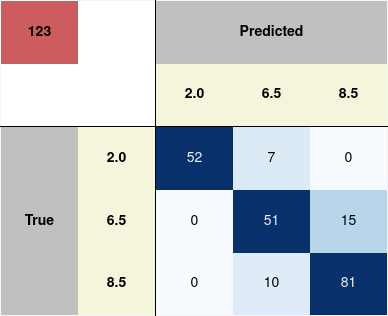

In [7]:
from IPython.display import display, Image
display(Image(data=img))

In [6]:
from PIL import Image
from io import BytesIO

image = Image.open(BytesIO(img))
print(image.size)  # Output will be (width, height)

(388, 316)


In [107]:
dft

In [110]:
await dfi.export_async(obj=dft, filename='test5.png', table_conversion='playwright', corner='Combined<br><br>Validation', timeout=60000)

TimeoutError: Locator.bounding_box: Timeout 30000ms exceeded.
Call log:
  - waiting for locator("#dfi_table table")


In [46]:
await dfi.export_async(obj=dft, filename='test4.png', table_conversion='playwright', corner='Combined<br><br>Train')

In [107]:
data['val']

In [74]:
def flatten(lst):
    flat = []
    for item in lst:
        if isinstance(item, list):
            flat.extend(flatten(item))
        else:
            flat.append(item)
    return flat

In [73]:
flatten(list((data['y_train'])))

[2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 2.0,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 8.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 6.5,
 2.0,
 2.0,
 2.0

In [45]:
df1, df2, df3 = await table_results(results_directory_path = '/home/mojtaba.kananisarche/Zh/models/2025-04-15|23:45:55|RNN_FACENET_5CV', unique_classes=[2,6.5,8.5], index=1, height=3, width=3)

In [46]:
df3

In [159]:
b = dfi.export_async(obj=df2, filename='test5.png', table_conversion='playwright', corner='Train')
await b

In [ ]:
kwargs = 



{'exclude_styles': False, 'encoding': 'utf-8', 'doctype_html': False, 'corner': 'test'}

In [11]:
if 'corner' in kwargs.keys():
    print(1)

1


In [9]:
a = {'uuid': 'ecb01', 'table_styles': [], 'caption': None, 'head': [[{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level0', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col0', 'is_visible': True, 'display_value': 'Predicted', 'attributes': 'colspan="3"', 'id': 'level0_col0'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col1', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col1'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col2', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col2'}], [{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level1', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '2.0', 'class': 'col_heading level1 col0', 'is_visible': True, 'display_value': '2.0', 'attributes': '', 'id': 'level1_col0'}, {'type': 'th', 'value': '6.5', 'class': 'col_heading level1 col1', 'is_visible': True, 'display_value': '6.5', 'attributes': '', 'id': 'level1_col1'}, {'type': 'th', 'value': '8.5', 'class': 'col_heading level1 col2', 'is_visible': True, 'display_value': '8.5', 'attributes': '', 'id': 'level1_col2'}]], 'index_lengths': {(0, 0): 3, (1, 0): 1, (1, 1): 1, (1, 2): 1}, 'body': [[{'type': 'th', 'value': 'True', 'class': 'row_heading level0 row0', 'is_visible': True, 'display_value': 'True', 'attributes': 'rowspan="3"', 'id': 'level0_row0'}, {'type': 'th', 'value': '2.0', 'class': 'row_heading level1 row0', 'is_visible': True, 'display_value': '2.0', 'attributes': '', 'id': 'level1_row0'}, {'type': 'td', 'value': 233, 'class': 'data row0 col0', 'is_visible': True, 'attributes': '', 'display_value': '233', 'id': 'row0_col0'}, {'type': 'td', 'value': 0, 'class': 'data row0 col1', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row0_col1'}, {'type': 'td', 'value': 0, 'class': 'data row0 col2', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row0_col2'}], [{'type': 'th', 'value': 'True', 'class': 'row_heading level0 row1', 'is_visible': False, 'display_value': 'True', 'attributes': '', 'id': 'level0_row1'}, {'type': 'th', 'value': '6.5', 'class': 'row_heading level1 row1', 'is_visible': True, 'display_value': '6.5', 'attributes': '', 'id': 'level1_row1'}, {'type': 'td', 'value': 0, 'class': 'data row1 col0', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row1_col0'}, {'type': 'td', 'value': 246, 'class': 'data row1 col1', 'is_visible': True, 'attributes': '', 'display_value': '246', 'id': 'row1_col1'}, {'type': 'td', 'value': 0, 'class': 'data row1 col2', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row1_col2'}], [{'type': 'th', 'value': 'True', 'class': 'row_heading level0 row2', 'is_visible': False, 'display_value': 'True', 'attributes': '', 'id': 'level0_row2'}, {'type': 'th', 'value': '8.5', 'class': 'row_heading level1 row2', 'is_visible': True, 'display_value': '8.5', 'attributes': '', 'id': 'level1_row2'}, {'type': 'td', 'value': 0, 'class': 'data row2 col0', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row2_col0'}, {'type': 'td', 'value': 0, 'class': 'data row2 col1', 'is_visible': True, 'attributes': '', 'display_value': '0', 'id': 'row2_col1'}, {'type': 'td', 'value': 286, 'class': 'data row2 col2', 'is_visible': True, 'attributes': '', 'display_value': '286', 'id': 'row2_col2'}]], 'cellstyle': [{'props': [('background-color', '#000000'), ('color', '#f1f1f1'), ('text-align', 'center')], 'selectors': ['row0_col0', 'row1_col1', 'row2_col2']}, {'props': [('background-color', '#ffffff'), ('color', '#000000'), ('text-align', 'center')], 'selectors': ['row0_col1', 'row0_col2', 'row1_col0', 'row1_col2', 'row2_col0', 'row2_col1']}], 'cellstyle_index': [], 'cellstyle_columns': [], 'table_attributes': None, 'exclude_styles': False, 'encoding': 'utf-8', 'doctype_html': False}

In [18]:
i = 3
print(f"{list(a.keys())[i]} - {a[list(a.keys())[i]]}")

head - [[{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level0', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col0', 'is_visible': True, 'display_value': 'Predicted', 'attributes': 'colspan="3"', 'id': 'level0_col0'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col1', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col1'}, {'type': 'th', 'value': 'Predicted', 'class': 'col_heading level0 col2', 'is_visible': False, 'display_value': 'Predicted', 'attributes': '', 'id': 'level0_col2'}], [{'type': 'th', 'value': '&nbsp;', 'class': 'blank', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '&nbsp;', 'class': 'blank level1', 'is_visible': True, 'display_value': '&nbsp;'}, {'type': 'th', 'value': '2.0', 'class': 'col_heading level1 col0', 'is_vi

In [22]:
a[list(a.keys())[3]][0]

[{'type': 'th',
  'value': '&nbsp;',
  'class': 'blank',
  'is_visible': True,
  'display_value': '&nbsp;'},
 {'type': 'th',
  'value': '&nbsp;',
  'class': 'blank level0',
  'is_visible': True,
  'display_value': '&nbsp;'},
 {'type': 'th',
  'value': 'Predicted',
  'class': 'col_heading level0 col0',
  'is_visible': True,
  'display_value': 'Predicted',
  'attributes': 'colspan="3"',
  'id': 'level0_col0'},
 {'type': 'th',
  'value': 'Predicted',
  'class': 'col_heading level0 col1',
  'is_visible': False,
  'display_value': 'Predicted',
  'attributes': '',
  'id': 'level0_col1'},
 {'type': 'th',
  'value': 'Predicted',
  'class': 'col_heading level0 col2',
  'is_visible': False,
  'display_value': 'Predicted',
  'attributes': '',
  'id': 'level0_col2'}]

In [26]:
a[list(a.keys)[2]]

TypeError: 'builtin_function_or_method' object is not iterable

In [31]:
a['head'][0][0]['display_value'] = 'Test'

In [213]:
df1, df2, df3 = await table_results(results_directory_path = '/home/mojtaba.kananisarche/Zh/models/2025-04-15|23:45:55|RNN_FACENET_5CV', unique_classes=[2,6.5,8.5], index=1)

In [ ]:
df1.set_table_styles(
    [{'selector': 'thead tr:nth-child(1) th:nth-child(1)',
      'props': [('background-color', 'IndianRed'), ('color', 'white')]}]
)

In [215]:
df1.apply(
    lambda x: ['font-weight: bold' if v == max(x) else '' for v in x],
    subset=['Predicted']
)

In [ ]:
df1.apply()

In [116]:
df2.style.background_gradient(axis=1, cmap='Greys')

In [114]:
df3.style.background_gradient(axis=1, cmap='Greys')

In [94]:
df3.style.background_gradient(axis=1)

In [40]:
df.columns = pd.MultiIndex.from_tuples([('True', '2.0'),
            ('True', '6.5'),
            ('True', '8.5')])

In [57]:
df.style.background_gradient(axis=0)

In [23]:
df.style.background_gradient()\
    .format(precision=3)\
    .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center')]}, 
                       {'selector': 'td', 'props': [('text-align', 'center')]}]).set_properties(**{'text-align': 'center'})

In [43]:
classification_report(y_true = [str(i) for i in data['y_train'][0]], y_pred = [str(i) for i in data['y_train_pred_class'][0]], zero_division=False, output_dict=True)

{'2': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0.0},
 '2.0': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 246.0},
 '6.5': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 256.0},
 '8.5': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 285.0},
 'accuracy': 0.6874205844980941,
 'macro avg': {'precision': 0.5,
  'recall': 0.5,
  'f1-score': 0.5,
  'support': 787.0},
 'weighted avg': {'precision': 0.6874205844980941,
  'recall': 0.6874205844980941,
  'f1-score': 0.6874205844980941,
  'support': 787.0}}

In [68]:
df = pd.DataFrame(data = confusion_matrix(y_true = [str(float(i)) for i in data['y_train'][0]], 
                 y_pred = [str(float(i)) for i in data['y_train_pred_class'][0]],
                 labels = [str(float(i)) for i in unique_classes]))
df.columns = pd.MultiIndex.from_product(iterables=[['True'], unique_classes])
df.index = pd.MultiIndex.from_product(iterables=[['Predicted'], unique_classes])

In [ ]:
df

True          
               2.0  6.5  8.5
Predicted 2.0  246    0    0
          6.5    0  256    0
          8.5    0    0  285

In [58]:
confusion_matrix(y_true = [str(float(i)) for i in data['y_train'][0]], 
                 y_pred = [str(float(i)) for i in data['y_train_pred_class'][0]],
                #  labels = ['2.0', '6.5', '8.5'])
                 labels = ['2.0', '8.5', '6.5'])

array([[246,   0,   0],
       [  0, 285,   0],
       [  0,   0, 256]])

In [54]:
set([str(i) for i in data['y_train_pred_class'][0]])

{'2', '6.5', '8.5'}

In [ ]:
def report(y_pred, y_true, unique_classes):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    thresholds = []

    # Sort unique classes and calculate thresholds
    unique_classes = sorted(unique_classes)
    for i in range(len(unique_classes) - 1):
        thresholds.append((unique_classes[i] + unique_classes[i + 1]) / 2)

    y_pred_classified = np.array([unique_classes[i] 
                                  for i in np.digitize(y_pred, thresholds, right=False)])
    
    unique_classes    = [str(float(i)) for i in unique_classes]
    y_true            = np.array([str(float(i)) for i in y_true])
    y_pred            = np.array([str(float(i)) for i in y_pred])
    y_pred_classified = np.array([str(float(i)) for i in y_pred_classified])


    classification_report_results = classification_report(y_true        = y_true,
                                                          y_pred        = y_pred_classified,
                                                          zero_division = False,
                                                          output_dict   = True)

    for cls in unique_classes:
        idx = y_true == cls
        if cls not in list(classification_report_results.keys()) or sum(idx) == 0:
            classification_report_results[cls] = {
                'precision': 0.0,
                'recall'   : 0.0,
                'f1-score' : 0.0,
                'mae'      : 0.0,
                'support'  : 0.0}
            continue
            
        y_true_cls = [float(i) for i in y_true[idx]]
        y_pred_cls = [float(i) for i in y_pred[idx]]
        mae = mean_absolute_error(y_true = y_true_cls, y_pred = y_pred_cls)
        classification_report_results[cls]['mae'] = mae
        classification_report_results[cls] = {i:classification_report_results[cls][i] 
                                              for i in ['precision', 'recall', 'f1-score', 'mae', 'support']}
    
    confusion_matrix_results = confusion_matrix(y_true=y_true, 
                                                y_pred=y_pred_classified)
    
    classification_report_results['confusion matrix'] = confusion_matrix_results

    classification_report_results = {i:classification_report_results[i] 
                                     for i in unique_classes + ['accuracy', 'macro avg', 'weighted avg', 'confusion matrix']}

    return [float(i) for i in y_pred], classification_report_results

In [125]:
y_true = [1,1,2]
y_pred = [1,2,3]
unique_classes = [1,2,3,4]

y = report(
    y_true = y_true,
    y_pred = y_pred,
    unique_classes=unique_classes
)

In [52]:
def pattern(lst):
    lookup = {}
    return [lookup.setdefault(val, len(lookup)) for val in lst]

def matches_pattern(list1, list2):
    return pattern(list1) == pattern(list2)

a = [1, 2, 3, 3, 2, 1]
b = ['x', 'y', 'z', 'z', 'y', 'x']
c = ['x', 'y', 'y', 'y', 'y', 'y']

print(matches_pattern(a, b))  # True
print(matches_pattern(a, c))  # False


True
False


In [55]:
lookup = {}
[lookup.setdefault(val, len(lookup)) for val in [1,2,3,3,2]]

[0, 1, 2, 2, 1]

In [64]:
y_true = [1,2,3,1,2]
y_pred = [2.2,2.9,3.1,1.2,2.6]
group_identifiers = ['x', 'y', 'y', 'x', 'r']
unique_classes = [1,2,3]

for i in y_true:
    if i not in unique_classes:
        pass
if not matches_pattern(y_true, group_identifiers):
    pass
if not len(y_true) == len(y_pred) == len(group_identifiers):
    pass

# Sort unique classes and calculate thresholds
unique_classes = sorted(unique_classes)
thresholds = [(unique_classes[i] + unique_classes[i + 1]) / 2 for i in range(len(unique_classes)-1)]


data = pd.DataFrame({'y_true' : y_true, 
                     'y_pred' : y_pred, 
                     'group_identifiers' : group_identifiers})

def assign_class(value, thresholds, unique_classes):
    return next((unique_classes[i] for i, t in enumerate(thresholds) if value < t), unique_classes[-1])
data['y_pred_class'] = data['y_pred'].apply(lambda x: assign_class(x, thresholds, unique_classes))

unique_classes = [str(float(i)) for i in unique_classes]
data['y_true'] = data['y_true'].astype(float).astype(str)
data['y_pred'] = data['y_pred'].astype(float).astype(str)
data['y_pred_class'] = data['y_pred_class'].astype(float).astype(str)

slices_results = classification_report(
    y_true = data['y_true'],
    y_pred = data['y_pred'],
    labels = unique_classes,
    output_dict=True,
    zero_division=False
)

for cls in unique_classes:
    filter = data['y_true'] == cls
    if sum(filter) == 0:
        slices_results[cls] = {
            'precision': 0.0,
            'recall'   : 0.0,
            'f1-score' : 0.0,
            'mae'      : 0.0,
            'support'  : 0.0}
        continue

    slices_results[cls]['mae'] = mean_absolute_error(
        y_true = [cls]*sum(filter), 
        y_pred = data[(data['y_true'] == cls)]['y_pred_class'].to_list()
        )
    
    slices_results[cls] = order_dict_by_key_list(slices_results[cls], 
                                                                ['precision', 'recall', 'f1-score', 'mae', 'support'])

slices_results['confusion matrix'] = confusion_matrix(
    y_true = data['y_true'], 
    y_pred = data['y_pred_class'], 
    labels=unique_classes)

slices_results = order_dict_by_key_list(slices_results, 
                                                       unique_classes + ['accuracy', 'macro avg', 'weighted avg', 'confusion matrix'])


In [ ]:
pd.DataFrame(columns = ['group_identifier', 'y_true', 'y_pred_majority', 'y_pred_average'])
for name, group in data.groupby('group_identifiers'):
    print(group)

  y_true y_pred group_identifiers y_pred_class
4    2.0    2.6                 r          3.0
  y_true y_pred group_identifiers y_pred_class
0    1.0    2.2                 x          2.0
3    1.0    1.2                 x          1.0
  y_true y_pred group_identifiers y_pred_class
1    2.0    2.9                 y          3.0
2    3.0    3.1                 y          3.0


In [58]:
slices_results

{'1.0': {'precision': 1.0,
  'recall': 0.5,
  'f1-score': 0.6666666666666666,
  'mae': 0.5,
  'support': 2.0},
 '2.0': {'precision': 0.6666666666666666,
  'recall': 1.0,
  'f1-score': 0.8,
  'mae': 0.0,
  'support': 2.0},
 '3.0': {'precision': 1.0,
  'recall': 1.0,
  'f1-score': 1.0,
  'mae': 0.0,
  'support': 1.0},
 'accuracy': 0.8,
 'macro avg': {'precision': 0.8888888888888888,
  'recall': 0.8333333333333334,
  'f1-score': 0.8222222222222223,
  'support': 5.0},
 'weighted avg': {'precision': 0.8666666666666666,
  'recall': 0.8,
  'f1-score': 0.7866666666666667,
  'support': 5.0},
 'confusion matrix': array([[1, 1, 0],
        [0, 2, 0],
        [0, 0, 1]])}

In [32]:
classification_report_results

{'1.0': {'precision': 0.5,
  'recall': 0.5,
  'f1-score': 0.5,
  'mae': 1.5,
  'support': 2.0},
 '2.0': {'precision': 0.0,
  'recall': 0.0,
  'f1-score': 0.0,
  'mae': 0.5,
  'support': 2.0},
 '3.0': {'precision': 0.0,
  'recall': 0.0,
  'f1-score': 0.0,
  'mae': 0.0,
  'support': 0.0},
 '4.0': {'precision': 0.0,
  'recall': 0.0,
  'f1-score': 0.0,
  'mae': 1.5,
  'support': 2.0},
 'macro avg': {'precision': 0.125,
  'recall': 0.125,
  'f1-score': 0.125,
  'support': 6.0},
 'weighted avg': {'precision': 0.16666666666666666,
  'recall': 0.16666666666666666,
  'f1-score': 0.16666666666666666,
  'support': 6.0},
 'confusion matrix': array([[1, 0, 0, 1],
        [0, 1, 1, 0],
        [0, 0, 0, 0],
        [1, 0, 0, 1]]),
 'micro avg': {'precision': 0.3333333333333333,
  'recall': 0.16666666666666666,
  'f1-score': 0.2222222222222222,
  'support': 6.0}}

In [ ]:
confusion_matrix(y_true = df['y_true'], y_pred = df['y_pred_class'], labels=unique_classes)

TypeError: got an unexpected keyword argument 'target_names'